# Logistic Regression for Binary Classification

## 1. Introduction

In the previous notebooks, we dealt with **continuous** target variables (like Fish Mass). 

But what if we want to predict a **categorical** outcome? 
*   Will a customer churn? (Yes/No)
*   Is this email spam? (Yes/No)
*   Is the tumor malignant? (Yes/No)

This is where **Logistic Regression** cornes in. Despite its name, it is used for **classification**, not regression.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

sns.set_theme(style="whitegrid")

## 2. Visualizing the Problem

We will use the `Churn Data Regression.csv` dataset. 
*   `has_churned`: 1 if the customer churned (left), 0 if they stayed.
*   `time_since_last_purchase`: Time since they last bought something.

Let's see why Linear Regression fails here.

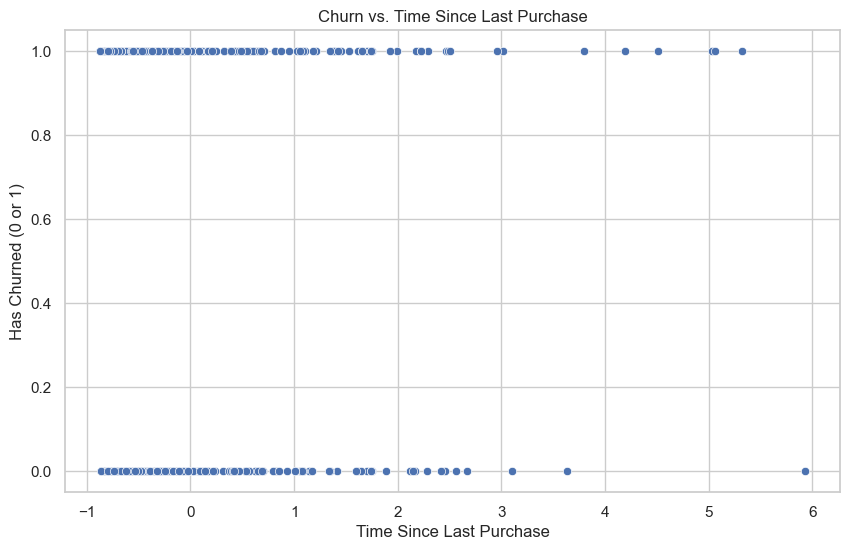

In [6]:
file_path = "../../00-data/Churn Data Regression.csv"
df = pd.read_csv(file_path)

plt.figure(figsize=(10, 6))
sns.scatterplot(x='time_since_last_purchase', y='has_churned', data=df)
plt.title('Churn vs. Time Since Last Purchase')
plt.xlabel('Time Since Last Purchase')
plt.ylabel('Has Churned (0 or 1)')
plt.show()

If we fit a straight line, it would predict values like -0.5 or 1.5, which are impossible as probabilities. We need a function that bounds the output between 0 and 1.

## 3. The Sigmoid Function and Log-Odds

Logistic Regression uses the **Sigmoid (Logistic) Function** to curve the straight line into an "S" shape.

$$ P(y=1) = \frac{1}{1 + e^{-z}} $$

Where $z = \beta_0 + \beta_1 x$ (the linear equation).

![Sigmoid Function](https://upload.wikimedia.org/wikipedia/commons/thumb/8/88/Logistic-curve.svg/1200px-Logistic-curve.svg.png)
*(Image Source: Wikimedia Commons)*

### **Log-Odds (The "Link" Function)**
The linear part of the model ($ \beta_0 + \beta_1 x $) predicts the **Log-Odds** of the event occurring.

$$ \log \left( \frac{P(y=1)}{1 - P(y=1)} \right) = \beta_0 + \beta_1 x $$

*   **Odds**: Probability of event happening / Probability of it not happening.
*   **Log-Odds**: The natural logarithm of the odds.

In [7]:
# Fitting the Logistic Model
X = df['time_since_last_purchase']
y = df['has_churned']
X_const = sm.add_constant(X)

# Note: We use Logit instead of OLS
model = sm.Logit(y, X_const).fit()
print(model.summary())

Optimization terminated successfully.
         Current function value: 0.683000
         Iterations 4
                           Logit Regression Results                           
Dep. Variable:            has_churned   No. Observations:                  400
Model:                          Logit   Df Residuals:                      398
Method:                           MLE   Df Model:                            1
Date:                Thu, 12 Mar 2026   Pseudo R-squ.:                 0.01464
Time:                        21:26:52   Log-Likelihood:                -273.20
converged:                       True   LL-Null:                       -277.26
Covariance Type:            nonrobust   LLR p-value:                  0.004384
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                       -0.0350      0.102     -0.345      0.730      -0.234

## 4. Interpreting the Metrics

The summary output looks different from OLS. Here are the key metrics:

### **1. Coefficients (Log-Odds)**
*   The `coef` column tells us the change in the **Log-Odds** of churning for a one-unit increase in $x$.
*   *This is hard for humans to understand intuitively.*

### **2. Odds Ratio (Exponential of Coef)**
*   To make it interpretable, we take the exponential: $e^{\beta_1}$.
*   **Interpretation**: If Odds Ratio is 1.5, it means for every 1 unit increase in time, the **odds** of churning increase by 50% (factor of 1.5).

### **3. Pseudo R-squared (McFadden's)**
*   Logistic regression doesn't have a true $R^2$. 
*   **Pseudo R-sq** compares the likelihood of your model (LL-Full) to a model with no predictors (LL-Null).
*   Values between 0.2 and 0.4 are considered "excellent" fit.

### **4. LLR p-value**
*   Like the F-statistic in OLS. Tests if the model is statistically significant overall.

In [8]:
# Calculating Odds Ratios
params = model.params
conf = model.conf_int()
conf['Odds Ratio'] = params
conf.columns = ['5%', '95%', 'Log-Odds']

# Calculate Odds Ratio
conf['Odds Ratio'] = np.exp(conf['Log-Odds'])

print(conf)

                                5%       95%  Log-Odds  Odds Ratio
const                    -0.233996  0.163957 -0.035019    0.965587
time_since_last_purchase  0.076908  0.461522  0.269215    1.308936


## 5. Confusion Matrix and Accuracy

To evaluate how well the model classifies, we compare predictions to actuals.

1.  **True Positives (TP)**: Predicted Churn, Actually Churned.
2.  **True Negatives (TN)**: Predicted Stay, Actually Stayed.
3.  **False Positives (FP)**: Predicted Churn, Actually Stayed (Type I Error).
4.  **False Negatives (FN)**: Predicted Stay, Actually Churned (Type II Error).

**Accuracy** = $\frac{TP + TN}{Total}$

In [9]:
# Making Predictions (Probabilities)
y_prob = model.predict(X_const)

# Convert probabilities to Class (0 or 1) using 0.5 threshold
y_pred = (y_prob > 0.5).astype(int)

# Confusion Matrix
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(y, y_pred)

print("Confusion Matrix:")
print(cm)
print(f"\nAccuracy: {accuracy_score(y, y_pred):.2f}")

Confusion Matrix:
[[141  59]
 [111  89]]

Accuracy: 0.57


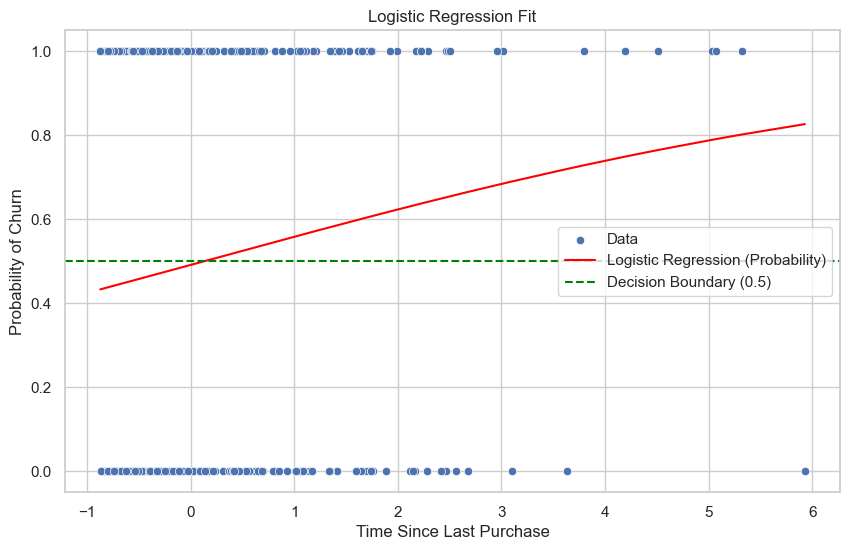

In [10]:
# Visualizing the Sigmoid Fit
plt.figure(figsize=(10, 6))
sns.scatterplot(x='time_since_last_purchase', y='has_churned', data=df, label='Data')

# Sort values for smooth line plot
sorted_index = X.argsort()
plt.plot(X.iloc[sorted_index], y_prob.iloc[sorted_index], color='red', label='Logistic Regression (Probability)')
plt.axhline(0.5, color='green', linestyle='--', label='Decision Boundary (0.5)')
plt.title('Logistic Regression Fit')
plt.xlabel('Time Since Last Purchase')
plt.ylabel('Probability of Churn')
plt.legend()
plt.show()

## 6. Exercises

**Exercise 1:** There is another variable `time_since_first_purchase`. Fit a logistic regression model using this variable instead.

**Exercise 2:** Calculate the Odds Ratio for `time_since_first_purchase`. What does it tell you?

**Exercise 3:** Calculate the accuracy of this new model. Is it better or worse than the previous one?

In [ ]:
# Exercise 1: Model with time_since_first_purchase



In [ ]:
# Exercise 2: Odds Ratio



In [ ]:
# Exercise 3: Accuracy

